# Inside Airbnb: load one city

Starter notebook for the CSE 6242 Airbnb project. It shows how to read every file
Inside Airbnb publishes for a city, cleans the usual gotchas, and makes a few quick
plots so you can sanity-check a city before analysing it.

**Before you start:** download the city with the script in `scripts/` (run from the repo root):

```bash
python scripts/download_data.py jersey-city --all-snapshots
```

Data lives in `data/<city>/<snapshot-date>/`. Nothing under `data/` is in git.

**What a snapshot is.** The date is the day Inside Airbnb scraped Airbnb for that city
(roughly quarterly). Relative to that day:

| file | contents | covers |
|---|---|---|
| `listings.csv.gz` | one row per listing, ~80-90 columns | the scrape day |
| `calendar.csv.gz` | one row per listing per day | the next 365 days |
| `reviews.csv.gz` | one row per review, with text | all history, for listings that were live on the scrape day |
| `listings_summary.csv` | compact listings table | the scrape day |
| `reviews_summary.csv` | `listing_id`, `date` only | all history |
| `neighbourhoods.csv` / `.geojson` | neighbourhood names and polygons | static |

All helper functions are defined in this notebook so you can read and change them.
Once they stabilise, move them into a shared module.

## Setup

In [3]:
import json
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Patch, Polygon as MplPolygon

warnings.filterwarnings("ignore", message="Pandas requires version")  # Anaconda 'bottleneck' noise


def find_repo_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the current directory until we find the repo (works from notebooks/ or the root)."""
    for p in [start, *start.parents]:
        if (p / "scripts" / "download_data.py").exists():
            return p
    raise FileNotFoundError("Run this notebook from inside the cse6242-airbnb repo.")


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data"

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

# One hue for single-series marks; orange only ever flags partial snapshots; a light->dark blue ramp for maps.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SEQ_BLUES = mpl.colors.LinearSegmentedColormap.from_list(
    "seq_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
mpl.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titleweight": "semibold", "axes.titlecolor": INK, "axes.titlesize": 11,
    "legend.frameon": False, "font.family": "sans-serif",
})

print("repo:", REPO_ROOT)
print("data:", DATA_DIR)

repo: c:\Users\isabelle\Documents\classes\CSE 6242\Project\cse6242-airbnb
data: c:\Users\isabelle\Documents\classes\CSE 6242\Project\cse6242-airbnb\data


## Configuration

Pick a city folder under `data/` and, optionally, a snapshot date. `None` means the latest snapshot.
The six project cities are `new-york-city`, `los-angeles`, `toronto`, `san-diego`, `clark-county-nv`, `jersey-city`.
Jersey City is the default because it is small and loads in seconds; New York City's calendar has 11 million rows.

In [4]:
CITY = "new-york-city"
SNAPSHOT = None  # e.g. "2025-12-28"

## Helpers: finding snapshots

`PARTIAL_SNAPSHOTS` lists scrapes that missed a large share of listings (measured on 2026-09-29 as the
share of listings present in *both* the first and last snapshot that are absent from that one).
Do not use them for counts, supply, or anything "per city"; per-listing analysis is still fine.

In [5]:
DATE_RE = re.compile(r"^\d{4}-\d{2}-\d{2}$")

PARTIAL_SNAPSHOTS: dict[str, dict[str, float]] = {
    "boston":          {"2025-12-27": 0.17, "2026-03-28": 0.55},
    "toronto":         {"2026-03-19": 0.28},
    "san-diego":       {"2026-03-29": 0.10},
    "clark-county-nv": {"2026-03-28": 0.54},
    "jersey-city":     {"2026-03-29": 0.51},
    # new-york-city and los-angeles: all snapshots complete
}


def available_cities() -> list[str]:
    """City folders under data/ that contain at least one snapshot folder."""
    if not DATA_DIR.exists():
        return []
    return sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir() and list_snapshots(p.name))


def list_snapshots(city: str) -> list[str]:
    """Snapshot dates downloaded for a city, oldest first."""
    city_dir = DATA_DIR / city
    if not city_dir.exists():
        return []
    return sorted(p.name for p in city_dir.iterdir() if p.is_dir() and DATE_RE.match(p.name))


def snapshot_dir(city: str, snapshot: str | None = None) -> Path:
    """Folder of one snapshot; latest when snapshot is None. Explains how to download if missing."""
    snaps = list_snapshots(city)
    if not snaps:
        raise FileNotFoundError(
            f"No data for '{city}' under {DATA_DIR}. Download it first (from the repo root):\n"
            f"    python scripts/download_data.py {city} --all-snapshots"
        )
    snapshot = snapshot or snaps[-1]
    if snapshot not in snaps:
        raise FileNotFoundError(f"'{city}' has no snapshot {snapshot}. Available: {snaps}")
    return DATA_DIR / city / snapshot


def is_partial(city: str, snapshot: str) -> bool:
    return snapshot in PARTIAL_SNAPSHOTS.get(city, {})


def data_inventory() -> pd.DataFrame:
    """One row per downloaded snapshot: file count, size, and whether the scrape is known to be partial."""
    rows = []
    for city in available_cities():
        for snap in list_snapshots(city):
            files = [p for p in (DATA_DIR / city / snap).iterdir() if p.is_file() and p.name != "manifest.json"]
            rows.append({
                "city": city, "snapshot": snap, "files": len(files),
                "size_mb": round(sum(p.stat().st_size for p in files) / 1e6, 1),
                "partial_scrape": is_partial(city, snap),
            })
    return pd.DataFrame(rows)

## Helpers: loaders

Each loader returns a pandas DataFrame with dates parsed, `t`/`f` columns as booleans, `$1,234.00` prices as
floats, and `city` / `snapshot` columns prepended so frames from different snapshots can be concatenated.
Columns are only converted when present, because the schema changed between snapshots
(79 columns in Sep 2025, 90 by Mar 2026; calendar prices were dropped in Dec 2025).

In [6]:
LISTING_DATE_COLS = ["last_scraped", "calendar_last_scraped", "host_since", "first_review", "last_review",
                     "price_quote_checkin_date", "price_quote_checkout_date"]
LISTING_BOOL_COLS = ["host_is_superhost", "host_has_profile_pic", "host_identity_verified",
                     "has_availability", "instant_bookable"]
LISTING_PCT_COLS = ["host_response_rate", "host_acceptance_rate"]


def parse_price(s: pd.Series) -> pd.Series:
    """'$1,234.00' -> 1234.0 (already-numeric columns pass through)."""
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    return pd.to_numeric(s.astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")


def _to_bool(s: pd.Series) -> pd.Series:
    return s.map({"t": True, "f": False}).astype("boolean")


def _to_fraction(s: pd.Series) -> pd.Series:
    """'95%' -> 0.95"""
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    return pd.to_numeric(s.astype("string").str.rstrip("%"), errors="coerce") / 100


def _tag(df: pd.DataFrame, city: str, folder: Path) -> pd.DataFrame:
    df.insert(0, "snapshot", folder.name)
    df.insert(0, "city", city)
    return df


def load_listings(city: str, snapshot: str | None = None, usecols: list[str] | None = None) -> pd.DataFrame:
    """Detailed listings (one row per listing, ~80-90 columns)."""
    folder = snapshot_dir(city, snapshot)
    df = pd.read_csv(folder / "listings.csv.gz", usecols=usecols, low_memory=False)
    for c in LISTING_DATE_COLS:
        if c in df:
            df[c] = pd.to_datetime(df[c], errors="coerce")
    for c in LISTING_BOOL_COLS:
        if c in df:
            df[c] = _to_bool(df[c])
    for c in LISTING_PCT_COLS:
        if c in df:
            df[c] = _to_fraction(df[c])
    if "price" in df:
        df["price"] = parse_price(df["price"])
    return _tag(df, city, folder)


def load_listings_summary(city: str, snapshot: str | None = None) -> pd.DataFrame:
    """Compact listings table (id, name, host, neighbourhood, lat/lon, room_type, price, review counts)."""
    folder = snapshot_dir(city, snapshot)
    df = pd.read_csv(folder / "listings_summary.csv")
    df["last_review"] = pd.to_datetime(df["last_review"], errors="coerce")
    df["price"] = parse_price(df["price"])
    return _tag(df, city, folder)


def load_calendar(city: str, snapshot: str | None = None, listing_ids=None) -> pd.DataFrame:
    """365 days of availability per listing. Pass listing_ids to load a subset (streams in chunks)."""
    folder = snapshot_dir(city, snapshot)
    path = folder / "calendar.csv.gz"
    if listing_ids is None:
        df = pd.read_csv(path)
    else:
        keep = set(listing_ids)
        df = pd.concat(
            [chunk[chunk["listing_id"].isin(keep)] for chunk in pd.read_csv(path, chunksize=1_000_000)],
            ignore_index=True,
        )
    df["date"] = pd.to_datetime(df["date"])
    df["available"] = df["available"].eq("t")
    for c in ("price", "adjusted_price"):  # only present in snapshots before Dec 2025
        if c in df:
            df[c] = parse_price(df[c])
    return _tag(df, city, folder)


def load_reviews(city: str, snapshot: str | None = None, with_text: bool = False) -> pd.DataFrame:
    """Reviews. with_text=False reads the small (listing_id, date) file; True reads the full comments."""
    folder = snapshot_dir(city, snapshot)
    df = pd.read_csv(folder / ("reviews.csv.gz" if with_text else "reviews_summary.csv"))
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    return _tag(df, city, folder)


def load_neighbourhoods(city: str, snapshot: str | None = None) -> pd.DataFrame:
    return pd.read_csv(snapshot_dir(city, snapshot) / "neighbourhoods.csv")


def load_geojson(city: str, snapshot: str | None = None) -> dict:
    with open(snapshot_dir(city, snapshot) / "neighbourhoods.geojson", encoding="utf-8") as f:
        return json.load(f)


def load_all_snapshots(city: str, loader=load_listings_summary, skip_partial: bool = False, **kwargs) -> pd.DataFrame:
    """Concatenate one loader across every snapshot of a city (the 'snapshot' column tells them apart)."""
    snaps = [s for s in list_snapshots(city) if not (skip_partial and is_partial(city, s))]
    return pd.concat([loader(city, s, **kwargs) for s in snaps], ignore_index=True)


def describe_columns(df: pd.DataFrame) -> pd.DataFrame:
    """dtype, non-null share and an example value per column: the quickest way to see what a file holds."""
    rows = []
    for c in df.columns:
        s = df[c]
        non_null = s.notna()
        example = s[non_null].iloc[0] if non_null.any() else None
        rows.append({"column": c, "dtype": str(s.dtype), "non_null": f"{non_null.mean():.0%}",
                     "example": str(example)[:60]})
    return pd.DataFrame(rows)

## Helpers: neighbourhood map

In [7]:
def plot_neighbourhoods(geojson: dict, values: pd.Series | None = None, ax=None, title: str | None = None,
                        cmap=SEQ_BLUES, colorbar_label: str | None = None):
    """Choropleth of the neighbourhood polygons. `values` is a Series indexed by neighbourhood name."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7.5, 7.5))
    patches, vals = [], []
    for feat in geojson["features"]:
        name = feat["properties"].get("neighbourhood")
        geom = feat["geometry"]
        polygons = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        for poly in polygons:
            patches.append(MplPolygon(np.asarray(poly[0]), closed=True))  # exterior ring; holes ignored
            vals.append(values.get(name, np.nan) if values is not None else np.nan)

    collection = PatchCollection(patches, edgecolor="white", linewidth=0.6)
    if values is not None:
        cmap = cmap.copy()
        cmap.set_bad(GRID)  # neighbourhoods without a value
        collection.set_cmap(cmap)
        collection.set_array(np.ma.masked_invalid(np.array(vals, dtype=float)))
        ax.figure.colorbar(collection, ax=ax, shrink=0.6, pad=0.01, label=colorbar_label)
    else:
        collection.set_facecolor("#cde2fb")
    ax.add_collection(collection)
    ax.autoscale_view()
    ax.set_aspect(1 / np.cos(np.radians(np.mean(ax.get_ylim()))))  # keep shapes roughly true at this latitude
    ax.set_axis_off()
    if title:
        ax.set_title(title)
    return ax

## What is downloaded?

In [8]:
inventory = data_inventory()
print(f"{len(inventory)} snapshots across {inventory['city'].nunique()} cities, {inventory['size_mb'].sum() / 1000:.1f} GB")
inventory

25 snapshots across 6 cities, 3.7 GB


,city,snapshot,files,size_mb,partial_scrape
0,clark-county-nv,2025-12-27,7,108.5,False
1,clark-county-nv,2026-03-28,7,76.4,True
2,clark-county-nv,2026-06-27,7,121.0,False
3,clark-county-nv,2026-09-20,7,123.5,False
4,jersey-city,2025-12-28,7,14.7,False
5,jersey-city,2026-03-29,7,10.2,True
6,jersey-city,2026-06-27,7,16.6,False
7,jersey-city,2026-09-21,7,17.5,False
8,los-angeles,2025-12-04,7,312.0,False
9,los-angeles,2026-03-16,7,316.9,False


## Listings

The main table. One row per listing as of the scrape day.

In [9]:
listings = load_listings(CITY, SNAPSHOT)

listings = load_all_snapshots(
    CITY,
    loader=load_listings
)

print(f"{CITY} snapshot {listings['snapshot'].iat[0]}: {len(listings):,} listings x {listings.shape[1]} columns")
listings.head(3)

new-york-city snapshot 2025-12-04: 132,417 listings x 92 columns


,city,snapshot,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw
0,new-york-city,2025-12-04,2539,https://www.airbnb.com/rooms/2539,20251204025441,2025-12-06,previous scrape,Superfast Wi-Fi. Clean & quiet home by the park,"Bright, serene room in a renovated apartment h...",Close to Prospect Park and Historic Ditmas Park,https://a0.muscache.com/pictures/hosting/Hosti...,2787,https://www.airbnb.com/users/show/2787,1.462506e+18,https://www.airbnb.com/users/profile/146250632...,John,2008-09-07,17.0,2.0,14.0,11.0,"New York, NY",Educated professional living in Brooklyn. I l...,within an hour,1.0,0.79,False,https://a0.muscache.com/im/pictures/user/User/...,https://a0.muscache.com/im/pictures/user/User/...,Gravesend,7.0,13.0,"['email', 'phone']",True,True,Neighborhood highlights,Kensington,Brooklyn,40.64529,-73.97238,Private room in condo,Private room,2,NaN,1 shared bath,1.0,NaN,"[""Cleaning available during stay"", ""Wine glass...",<NA>,30.0,730.0,30.0,30.0,730.0,730.0,30.0,730.0,NaN,True,30,60,90,364,2025-12-06,9,0,0,26,0,0,NaN,2015-12-04,2018-10-19,4.89,4.88,5.00,5.00,5.0,4.75,4.88,NaN,False,7,1,6,0,0.07,NaT,NaT,NaN,NaN,NaN
1,new-york-city,2025-12-04,2595,https://www.airbnb.com/rooms/2595,20251204025441,2025-12-05,city scrape,Skylit Studio Oasis | Midtown Manhattan Sanctuary,Prime Midtown | Spacious 500 Sq Ft | Pyramid S...,Centrally located in the heart of Manhattan ju...,https://a0.muscache.com/pictures/hosting/Hosti...,2845,https://www.airbnb.com/users/show/2845,1.462506e+18,https://www.airbnb.com/users/profile/146250632...,Jennifer,2008-09-09,17.0,2.0,14.0,11.0,"Woodstock, NY",A New Yorker since 2000! My passion is creatin...,within a day,0.6,0.26,False,https://a0.muscache.com/im/pictures/user/50fc5...,https://a0.muscache.com/im/pictures/user/50fc5...,Midtown,7.0,9.0,"['email', 'phone', 'work_email']",True,True,Neighborhood highlights,Midtown,Manhattan,40.75356,-73.98559,Entire rental unit,Entire home/apt,1,1.0,1 bath,0.0,1.0,"[""Cleaning available during stay"", ""Dishes and...",<NA>,30.0,1125.0,30.0,30.0,1125.0,1125.0,30.0,1125.0,NaN,True,30,60,90,319,2025-12-05,47,0,0,27,0,0,NaN,2009-11-21,2022-06-21,4.68,4.73,4.63,4.77,4.8,4.81,4.40,NaN,False,3,3,0,0,0.24,NaT,NaT,NaN,NaN,NaN
2,new-york-city,2025-12-04,6848,https://www.airbnb.com/rooms/6848,20251204025441,2025-12-04,city scrape,Only 2 stops to Manhattan studio,Comfortable studio apartment wi

In [10]:
# Every column with its type, how often it is filled, and an example.
# Note the columns that are 100% empty in newer snapshots (host_since, host_response_rate, instant_bookable, ...).
describe_columns(listings)

,column,dtype,non_null,example
0,city,str,100%,new-york-city
1,snapshot,str,100%,2025-12-04
2,id,int64,100%,2539
3,listing_url,str,100%,https://www.airbnb.com/rooms/2539
4,scrape_id,int64,100%,20251204025441
...,...,...,...,...
87,price_quote_checkin_date,datetime64[us],51%,2026-12-20 00:00:00
88,price_quote_checkout_date,datetime64[us],51%,2027-01-19 00:00:00
89,price_quote_total_price,float64,47%,3518.0
90,price_quote_price_per_night,float64,47%,117.27


In [11]:
print(listings["room_type"].value_counts().to_string(), "\n")
print("price (USD per night):")
print(listings["price"].describe().round(0).to_string(), "\n")
print("top neighbourhoods:")
print(listings["neighbourhood_cleansed"].value_counts().head(10).to_string())

room_type
Entire home/apt    72018
Private room       57798
Hotel room          1650
Shared room          951 

price (USD per night):
count    62356.0
mean       279.0
std        553.0
min          5.0
25%         97.0
50%        171.0
75%        298.0
max      31538.0 

top neighbourhoods:
neighbourhood_cleansed
Bedford-Stuyvesant    9250
Midtown               7766
Williamsburg          7077
Harlem                6112
Hell's Kitchen        5793
Upper West Side       5332
Upper East Side       5219
Bushwick              4769
Crown Heights         3941
East Village          3284


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


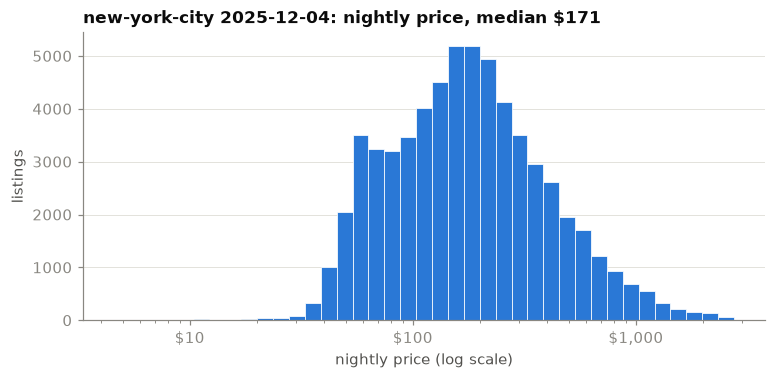

In [12]:
price = listings["price"].dropna()
price = price[price > 0]
bins = np.logspace(np.log10(price.min()), np.log10(price.quantile(0.995)), 40)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(price, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("nightly price (log scale)")
ax.set_ylabel("listings")
ax.set_title(f"{CITY} {listings['snapshot'].iat[0]}: nightly price, median ${price.median():,.0f}")
plt.show()

**About `price`.** It is the nightly rate Airbnb quoted for the check-in date the scraper asked about, as a
`$1,234.00` string in the file (the loader converts it). Roughly 10% of listings have no price because they
had no availability. Snapshots from March 2026 on also carry `price_quote_price_per_night` (numeric) and the
raw quote JSON in `price_quote_raw`.

## Calendar

One row per listing per day for the 365 days after the scrape. Snapshots before December 2025 also have
per-night `price` and `adjusted_price`; later ones only have availability and min/max nights.

In [13]:
calendar = load_calendar(CITY, SNAPSHOT)
print(f"{len(calendar):,} rows, {calendar['listing_id'].nunique():,} listings, "
      f"{calendar['date'].min().date()} to {calendar['date'].max().date()}")
print("columns:", list(calendar.columns))
calendar.head()

10,920,077 rows, 29,918 listings, 2026-09-14 to 2027-09-14
columns: ['city', 'snapshot', 'listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']


,city,snapshot,listing_id,date,available,minimum_nights,maximum_nights
0,new-york-city,2026-09-14,23545,2026-09-15,False,30,1125
1,new-york-city,2026-09-14,23545,2026-09-16,False,30,1125
2,new-york-city,2026-09-14,23545,2026-09-17,False,30,1125
3,new-york-city,2026-09-14,23545,2026-09-18,False,30,1125
4,new-york-city,2026-09-14,23545,2026-09-19,False,30,1125


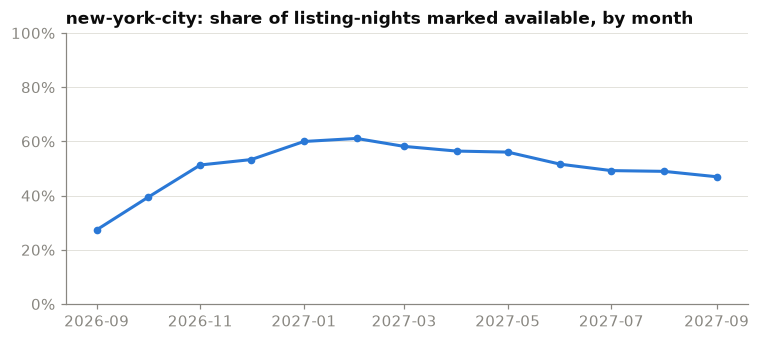

This snapshot's calendar has no price columns (dropped by Inside Airbnb in Dec 2025).


In [14]:
by_month = calendar.groupby(calendar["date"].dt.to_period("M"))["available"].mean()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(by_month.index.to_timestamp(), by_month.values, color=BLUE, linewidth=2, marker="o", markersize=4)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_title(f"{CITY}: share of listing-nights marked available, by month")
plt.show()

if "price" in calendar:
    med = calendar.groupby(calendar["date"].dt.to_period("M"))["price"].median()
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.plot(med.index.to_timestamp(), med.values, color=BLUE, linewidth=2, marker="o", markersize=4)
    ax.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("${x:,.0f}"))
    ax.set_title(f"{CITY}: median nightly calendar price, by month")
    plt.show()
else:
    print("This snapshot's calendar has no price columns (dropped by Inside Airbnb in Dec 2025).")

In [15]:
listings.columns

Index(['city', 'snapshot', 'id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'picture_url',
       'host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months',
       'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_about', 'host_response_time', 'host_response_rate',
       'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed',
       'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms',
       'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum

## Reviews

`with_text=False` (default) loads only `listing_id` and `date`, which is enough for review counts over time and
is fast. `with_text=True` loads the full comments (hundreds of MB for the big cities).
Remember: a snapshot only contains reviews of listings that were live on its scrape day.

999,099 reviews, 2009-05-25 to 2026-09-14


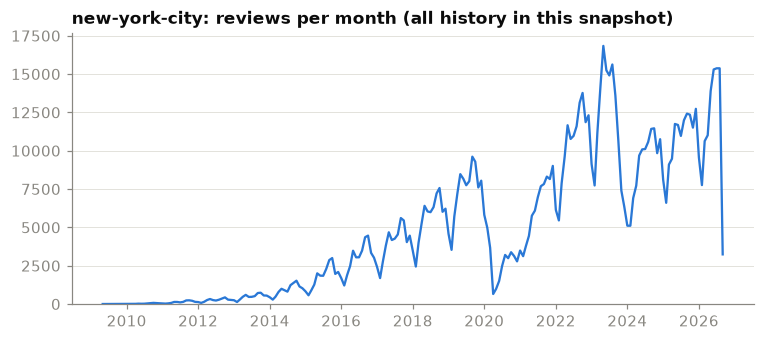

In [16]:
reviews = load_reviews(CITY, SNAPSHOT)
print(f"{len(reviews):,} reviews, {reviews['date'].min().date()} to {reviews['date'].max().date()}")

per_month = reviews.groupby(reviews["date"].dt.to_period("M")).size()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(per_month.index.to_timestamp(), per_month.values, color=BLUE, linewidth=1.5)
ax.set_ylim(bottom=0)
ax.set_title(f"{CITY}: reviews per month (all history in this snapshot)")
plt.show()

In [17]:
reviews.head(5)

,city,snapshot,listing_id,date
0,new-york-city,2026-09-14,2539,2015-12-04
1,new-york-city,2026-09-14,2539,2016-08-27
2,new-york-city,2026-09-14,2539,2016-10-01
3,new-york-city,2026-09-14,2539,2017-02-20
4,new-york-city,2026-09-14,2539,2017-03-19


## Neighbourhoods

`neighbourhood_cleansed` in listings uses the same names as the GeoJSON polygons, so a per-neighbourhood
aggregate can be drawn directly. Larger cities also have `neighbourhood_group_cleansed` (e.g. NYC boroughs).

233 polygons, 224 neighbourhoods with listings


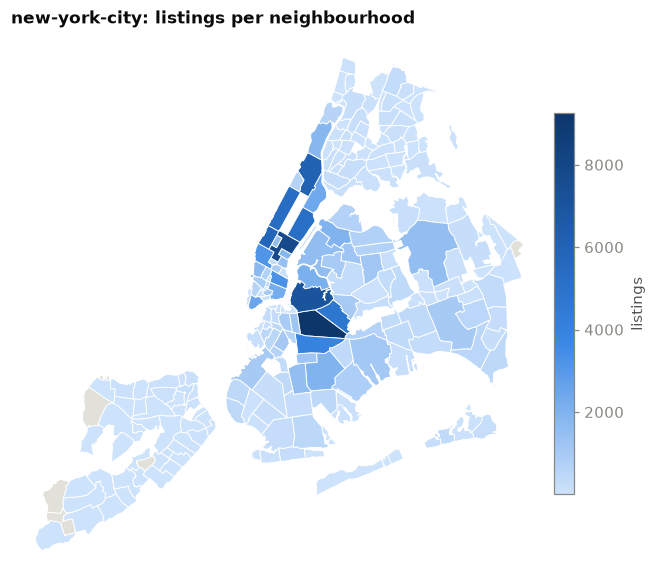

,listings
neighbourhood_cleansed,
Bedford-Stuyvesant,9250
Midtown,7766
Williamsburg,7077
Harlem,6112
Hell's Kitchen,5793
Upper West Side,5332
Upper East Side,5219
Bushwick,4769
Crown Heights,3941


In [18]:
geo = load_geojson(CITY, SNAPSHOT)
per_hood = listings.groupby("neighbourhood_cleansed").size().rename("listings")
print(f"{len(geo['features'])} polygons, {per_hood.size} neighbourhoods with listings")

plot_neighbourhoods(geo, per_hood, title=f"{CITY}: listings per neighbourhood", colorbar_label="listings")
plt.show()

per_hood.sort_values(ascending=False).head(10).to_frame()

## Comparing snapshots

Use the summary files to see how the city changed between scrapes. Partial scrapes are shown in orange:
their counts are undercounts, not real drops.

,snapshot,listings,median_price,entire_home_share,partial_scrape
0,2025-12-04,36261,$nan,54%,False
1,2026-03-16,35979,$160,54%,False
2,2026-06-14,30555,$176,55%,False
3,2026-09-14,29918,$182,55%,False


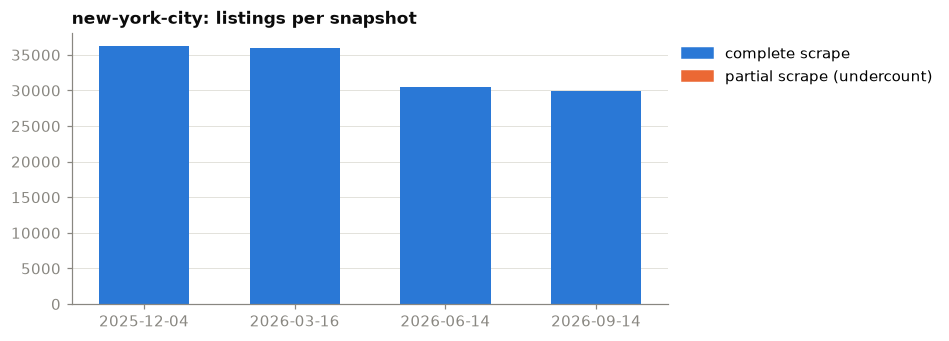

In [19]:
rows = []
for snap in list_snapshots(CITY):
    summary = load_listings_summary(CITY, snap)
    rows.append({
        "snapshot": snap,
        "listings": len(summary),
        "median_price": summary["price"].median(),
        "entire_home_share": summary["room_type"].eq("Entire home/apt").mean(),
        "partial_scrape": is_partial(CITY, snap),
    })
snapshots = pd.DataFrame(rows)
display(snapshots.style.format({"median_price": "${:,.0f}", "entire_home_share": "{:.0%}"}))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(snapshots["snapshot"], snapshots["listings"], width=0.6,
       color=[ORANGE if p else BLUE for p in snapshots["partial_scrape"]])
ax.set_title(f"{CITY}: listings per snapshot")
ax.legend(handles=[Patch(color=BLUE, label="complete scrape"), Patch(color=ORANGE, label="partial scrape (undercount)")],
          loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

## Caveats and next steps

- **Partial scrapes.** Exclude the snapshots in `PARTIAL_SNAPSHOTS` from any per-city counts or
  quarter-over-quarter comparisons. `load_all_snapshots(..., skip_partial=True)` does that for you.
- **Review history** should come from the *latest* snapshot; earlier ones contain nothing newer ones lack.
- **Columns that went empty in 2026:** `host_since`, `host_response_rate`, `host_acceptance_rate`,
  `instant_bookable`. Take them from an older snapshot (joined on `id`) if you need them.
- **IDs are 64-bit integers.** Keep them as `int64` in pandas; convert to strings before handing them to
  JavaScript / D3, which loses precision above 2^53.
- **`amenities`** is a JSON list in a string: `listings["amenities"].map(json.loads)`.
- **Big cities.** New York's calendar is 11 million rows; load a subset with `load_calendar(..., listing_ids=...)`
  or restrict `load_listings(..., usecols=[...])` to the columns you need.

## Combine data


In [20]:
def drop_listings(df, needed_factors):
    df = df.copy()
    df = df.dropna(subset=needed_factors)
    return df

def dedupe_listings(df, wanted_factors):
    df = df.copy()
    df["completeness"] = df[wanted_factors].notna().sum(axis=1)

    # select snapshot based on:
    #   1. highest completeness
    #   2. newest snapshot
    df = df.sort_values(by=["id", "completeness", "snapshot"],ascending=[True, False, False])

    # keep the best snapshot for each listing
    deduped = (df.drop_duplicates(subset="id", keep="first").drop(columns="completeness").reset_index(drop=True))
    return deduped


def load_all_cities(cities, needed_factors, wanted_factors):
    df = []
    for city in cities:
        # Load all snapshots for the city
        city_df = load_all_snapshots(
            city,
            loader=load_listings
        )
        print(f"  {len(city_df):,} listings loaded from {city_df['snapshot'].nunique()} snapshots")

        # drop listings that are missing any of the needed factors
        city_df = drop_listings(city_df, needed_factors)

        # deduplicate listings across snapshots
        city_df = dedupe_listings(city_df,wanted_factors)

        df.append(city_df)
        print(f"  {len(city_df):,} listings retained")

    # Combine all cities
    combined = pd.concat(df, ignore_index=True)
    print(f"\nTotal listings: {len(combined):,}")

    return combined

In [21]:
needed_factors = [
    "price_quote_price_per_night",
    "latitude",
    "longitude",
]


wanted_factors = [
    "price_quote_price_per_night",
    "property_type",
    "room_type",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "amenities",
    "neighbourhood_cleansed",
    "latitude",
    "longitude",
    "minimum_nights"
]

In [22]:
def column_checker(cities):
    fields = set()
    city_fields = {}
    for city in cities:
        # Load all snapshots for the city
        city_df = load_all_snapshots(
            city,
            loader=load_listings)
        fields.update(city_df.columns)
        city_fields[city] = set(city_df.columns)
    for city in cities:
        missing = fields - city_fields[city]
        if missing:
            print(f"{city} is missing columns: {missing}")

        

In [24]:
column_checker(["new-york-city", "los-angeles", "toronto", "san-diego", "clark-county-nv", "jersey-city"])

In [25]:
loaded_cities = load_all_cities(["new-york-city", "los-angeles", "toronto", "san-diego", "clark-county-nv", "jersey-city"], needed_factors, wanted_factors)

  132,417 listings loaded from 4 snapshots
  26,192 listings retained
  179,205 listings loaded from 4 snapshots
  47,978 listings retained
  81,340 listings loaded from 4 snapshots
  22,626 listings retained
  64,483 listings loaded from 5 snapshots
  13,278 listings retained
  67,779 listings loaded from 4 snapshots
  19,571 listings retained
  7,710 listings loaded from 4 snapshots
  2,464 listings retained

Total listings: 132,109
